# Validación independiente del modelo satélite de mora de consumo

**Objeto.** El modelo satélite del [proyecto 01](../01-riesgo-estres-consumo), que proyecta el ICV 90+ de consumo del sistema
bajo escenarios macro y alimenta el cálculo de pérdida incremental y los límites de apetito.

**Marco.** Las pruebas siguen los ejes de una validación de riesgo de modelo (SR 11-7 de la Reserva Federal; en Colombia, los
principios de gestión de riesgo de modelo del SIAR, Circular Externa 018 de 2021 de la SFC): integridad de datos, solidez
conceptual, desempeño fuera de muestra frente a retadores, estabilidad, diagnóstico estadístico y razonabilidad de escenarios
y supuestos. Cada hallazgo lleva severidad, evidencia y remediación.

**Independencia.** El validador recalcula los datos sin el código del desarrollador, reestima en cada corte (incluida la
selección de rezagos, que es parte del modelo) y construye sus propios retadores.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd())); sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import validacion as V
import estres as E
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
d = E.base_modelo(); s = E.series_consumo(); p = E.por_producto()
tabla = E.seleccionar_rezagos(d); rez = E.rezagos_elegidos(tabla); sat = E.ajustar(d, rez)
HALLAZGOS = []
def hallazgo(id_, area, severidad, evidencia, remediacion):
    HALLAZGOS.append({"id": id_, "área": area, "severidad": severidad, "evidencia": evidencia, "remediación": remediacion})
print("Modelo del desarrollador:", rez, "| n =", len(sat.muestra))

Modelo del desarrollador: {'tpm': 9, 'inflacion': 15, 'crec': 12} | n = 116


## 1. Integridad de datos

In [2]:
rep = V.replicar_icv()
print(f"Meses comparados: {len(rep)} | diferencia máxima validador vs desarrollador: {rep.dif_pb.abs().max():.4f} pb")
assert rep.dif_pb.abs().max() < 0.01

Meses comparados: 140 | diferencia máxima validador vs desarrollador: 0.0000 pb


**Resultado.** La serie se replica exactamente desde la capa de datos. Sin hallazgo. Queda como limitación de diseño, no de
implementación, que el ICV se mueve con castigos y ventas de cartera que la fuente no separa.

## 2. Desempeño fuera de tiempo: ¿habría anticipado el ciclo 2023–2024?

Se estima el modelo con datos hasta junio de 2022, antes del deterioro, repitiendo la selección de rezagos, y se pronostica 24
meses con la macro efectivamente observada. Es la prueba central de un modelo de estrés: si hubiera conocido la macro,
¿habría proyectado la mora? Retadores: paseo aleatorio (la mora se queda donde está), AR(1) sin macro y regresión estática
sin persistencia.

Rezagos que el procedimiento elige con datos a 2022-06: {'tpm': 9, 'inflacion': 9, 'crec': 18} (con todos los datos: {'tpm': 9, 'inflacion': 15, 'crec': 12} )
RMSE 24 meses (pb): {'desarrollador': 224, 'ar1': 149, 'estatico': 50, 'paseo_aleatorio': 163}
Pico observado 4.77% | pico proyectado por el modelo 9.00%


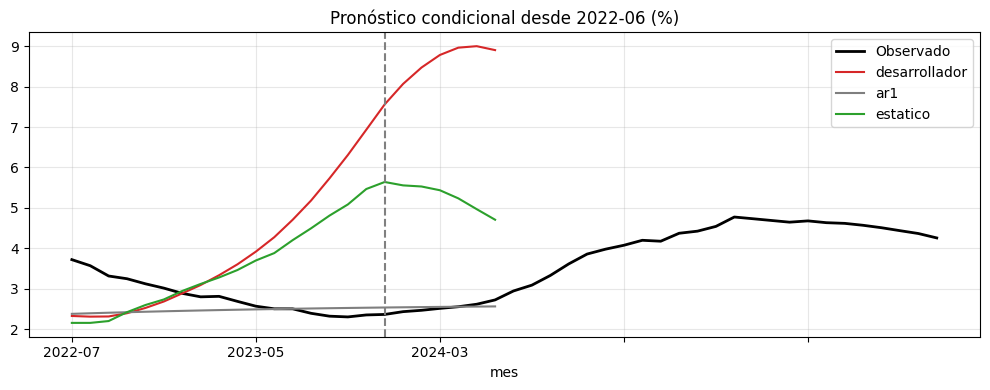

In [3]:
f = V.fuera_de_tiempo(d, "2022-06", 24)
rmse = {c: float(np.sqrt(((f[c] - f.observado) ** 2).mean()) * 1e4) for c in ["desarrollador", "ar1", "estatico", "paseo_aleatorio"]}
print("Rezagos que el procedimiento elige con datos a 2022-06:", f.attrs["rez"], "(con todos los datos:", rez, ")")
print("RMSE 24 meses (pb):", {k: round(v) for k, v in rmse.items()})
print(f"Pico observado {f.observado.max():.2%} | pico proyectado por el modelo {f.desarrollador.max():.2%}")
fig, ax = plt.subplots(figsize=(10, 4))
(100 * d.icv90.loc["2021-01":"2024-12"]).plot(ax=ax, color="k", lw=2, label="Observado")
for c, col in [("desarrollador", "tab:red"), ("ar1", "tab:gray"), ("estatico", "tab:green")]:
    (100 * f[c]).plot(ax=ax, color=col, label=c)
ax.axvline(list(d.loc["2021-01":"2024-12"].index).index("2022-06"), color="0.5", ls="--")
ax.set_title("Pronóstico condicional desde 2022-06 (%)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "fuera_de_tiempo.png", dpi=130); plt.show()

In [4]:
sobre = f.desarrollador.max() / f.observado.max() - 1
if rmse["desarrollador"] > rmse["paseo_aleatorio"]:
    hallazgo("H1", "Desempeño", "Alta",
             f"Desde 2022-06 el modelo proyecta un pico de {f.desarrollador.max():.1%} frente a {f.observado.max():.1%} observado "
             f"(+{sobre:.0%}); RMSE {rmse['desarrollador']:.0f} pb frente a {rmse['paseo_aleatorio']:.0f} pb del paseo aleatorio.",
             "Reemplazar la persistencia de la variable dependiente por persistencia en el error (sección 7).")
print(HALLAZGOS[-1]["evidencia"] if HALLAZGOS else "Sin hallazgo")

Desde 2022-06 el modelo proyecta un pico de 9.0% frente a 4.8% observado (+89%); RMSE 224 pb frente a 163 pb del paseo aleatorio.


**Lectura.** El modelo acierta la dirección y el momento del giro, pero se dispara: la combinación de un coeficiente
autorregresivo cercano a 0,8 con los regresores macro acumula los choques mes a mes y dobla el pico. La regresión estática,
que no tiene esa dinámica, sigue mucho mejor la trayectoria. Ahí está la pista para la remediación.

## 3. Backtest de origen rodante

In [5]:
orig = [str(x) for x in pd.period_range("2020-06", "2025-08", freq="3M")]
b = pd.concat([V.backtest_rodante(d, orig, 12), V.backtest_remediado(d, orig, 12)])
tab_rmse = b.groupby(["modelo", "h"]).error_pb.apply(lambda e: np.sqrt((e ** 2).mean())).unstack()[[1, 3, 6, 12]]
print(f"{len(orig)} orígenes trimestrales, de {orig[0]} a {orig[-1]}; cada uno reestima y vuelve a seleccionar rezagos.")
tab_rmse.round(1)

21 orígenes trimestrales, de 2020-06 a 2025-06; cada uno reestima y vuelve a seleccionar rezagos.


h,1,3,6,12
modelo,,,,
ar1,18.2000,52.6000,82.9000,109.6000
desarrollador,19.0000,56.0000,94.1000,135.1000
estatico,48.4000,76.5000,99.8000,107.4000
paseo_aleatorio,17.2000,47.5000,69.4000,103.0000
remediado,22.9000,56.4000,67.7000,71.2000


In [6]:
x = b[b.h == 12].pivot(index="origen", columns="modelo", values="error_pb").dropna()
dm_rw = V.diebold_mariano(x.desarrollador.values, x.paseo_aleatorio.values, 12)
dm_rem = V.diebold_mariano(x.remediado.values, x.paseo_aleatorio.values, 12)
print(f"Diebold-Mariano a 12 meses (negativo = mejor que el paseo aleatorio), {len(x)} orígenes:")
print(f"  desarrollador: DM = {dm_rw[0]:.2f}, p = {dm_rw[1]:.3f}")
print(f"  remediado:     DM = {dm_rem[0]:.2f}, p = {dm_rem[1]:.3f}")
if tab_rmse.loc["desarrollador", 12] > tab_rmse.loc["paseo_aleatorio", 12]:
    hallazgo("H2", "Desempeño", "Alta",
             f"A 12 meses el RMSE del modelo es {tab_rmse.loc['desarrollador',12]:.0f} pb frente a "
             f"{tab_rmse.loc['paseo_aleatorio',12]:.0f} pb del paseo aleatorio; no agrega valor sobre no hacer nada.",
             "No usar para proyección hasta superar al paseo aleatorio en el backtest rodante.")

Diebold-Mariano a 12 meses (negativo = mejor que el paseo aleatorio), 21 orígenes:
  desarrollador: DM = 1.72, p = 0.085
  remediado:     DM = -3.15, p = 0.002


Con 21 orígenes trimestrales y errores a 12 meses solapados, el contraste de Diebold-Mariano tiene poca potencia: sirve
para descartar diferencias grandes, no para certificar que un modelo es mejor. Por eso la decisión se apoya también en la
prueba fuera de tiempo y en la estabilidad.

## 4. Estabilidad

In [7]:
cortes = ["2021-12", "2022-12", "2023-12", "2024-12", s.index[-1]]
est = V.estabilidad_seleccion(d, cortes)
est

,fin,n,ganador_libre,signos_libre_ok,ganador_restringido,especificaciones_coherentes
0,2021-12,48,6/9/12,False,9/15/15,12
1,2022-12,60,3/9/12,False,9/9/15,11
2,2023-12,72,3/9/12,False,3/15/15,9
3,2024-12,84,3/12/24,False,12/12/12,29
4,2026-08,104,3/12/24,False,9/15/12,43


In [8]:
rec = V.coeficientes_recursivos(d, rez, cortes)
rec.round(4)

,b_ylag,b_tpm,b_inflacion,b_crec,p_tpm,p_inflacion,p_crec
fin,,,,,,,
2021-12,0.7955,-0.0128,0.0099,0.0124,0.2952,0.1641,0.0201
2022-12,0.8140,-0.0086,0.0084,0.0085,0.3343,0.1505,0.0063
2023-12,0.8181,-0.0066,0.0073,0.0085,0.4026,0.2178,0.0000
2024-12,0.8605,-0.0007,0.0090,0.0035,0.9191,0.1683,0.0000
2026-08,0.8660,0.0033,0.0050,0.0029,0.1073,0.0564,0.0000


In [9]:
neg = rec.index[rec.b_tpm < 0].tolist()
if neg:
    hallazgo("H3", "Estabilidad", "Alta",
             f"Con los rezagos finales, el coeficiente de la TPM es negativo en los cortes {', '.join(neg)} y solo se vuelve "
             f"positivo con la muestra completa (p = {rec.p_tpm.iloc[-1]:.2f}). La especificación elegida cambia en cada corte: "
             f"{', '.join(est.ganador_restringido.astype(str))}.",
             "Fijar la especificación con criterio económico y documentar; reportar bandas de coeficientes por corte.")
print(HALLAZGOS[-1]["evidencia"])

Con los rezagos finales, el coeficiente de la TPM es negativo en los cortes 2021-12, 2022-12, 2023-12, 2024-12 y solo se vuelve positivo con la muestra completa (p = 0.11). La especificación elegida cambia en cada corte: 9/15/15, 9/9/15, 3/15/15, 12/12/12, 9/15/12.


## 5. Diagnóstico estadístico

In [10]:
dg = V.diagnostico_residuos(sat)
st = V.sin_tpm(d, rez)
print({k: (round(v, 4) if not isinstance(v, dict) else {a: round(b, 1) for a, b in v.items()}) for k, v in dg.items()})
print(f"AIC con TPM {sat.resultado.aic:.1f} | sin TPM {st['aic_sin_tpm']:.1f}")
hallazgo("H4", "Solidez conceptual", "Media",
         f"Colinealidad TPM-inflación (VIF {dg['vif']['tpm']:.1f} y {dg['vif']['inflacion']:.1f}); el modelo sin TPM tiene mejor AIC "
         f"({st['aic_sin_tpm']:.1f} frente a {sat.resultado.aic:.1f}). El escenario de tasas no tiene un canal propio identificado.",
         "Diseñar escenarios coherentes TPM-inflación (no choques independientes) o usar tasa real.")
hallazgo("H5", "Diagnóstico", "Media",
         f"Residuos autocorrelacionados (Ljung-Box p = {dg['ljung_box_p12']:.1e}; Breusch-Godfrey p = {dg['breusch_godfrey_p']:.1e}), "
         f"no normales (Jarque-Bera p = {dg['jarque_bera_p']:.1e}) y con heterocedasticidad condicional (ARCH p = {dg['arch_p']:.1e}).",
         "Mantener errores HAC para inferencia; modelar la dinámica del error (sección 7); intervalos por bootstrap.")

{'ljung_box_p12': 0.0, 'breusch_godfrey_p': 0.0, 'jarque_bera_p': 0.0, 'arch_p': 0.0004, 'vif': {'ylag': np.float64(3.8), 'tpm': np.float64(9.8), 'inflacion': np.float64(12.1), 'crec': np.float64(1.4), 'covid': np.float64(1.2)}}
AIC con TPM -380.2 | sin TPM -381.3


## 6. Razonabilidad de escenarios y supuestos

In [11]:
esc = E.trayectorias_macro(d)
proy = {k: E.proyectar(sat, d, v) for k, v in esc.items()}
sev = V.severidad_relativa(proy, d)
print(sev)
if not sev.loc["Severo", "supera_historia"]:
    hallazgo("H6", "Escenarios", "Alta",
             f"El pico del escenario severo ({sev.loc['Severo','pico']:.2%}) queda por debajo del máximo observado "
             f"({sev.maximo_historico.iloc[0]:.2%}, {sev.mes_max_historico.iloc[0]}). Un severo menos duro que la historia "
             "reciente no sirve para fijar capacidad de riesgo.",
             "Calibrar el severo por percentil de la distribución histórica de choques o por estrés inverso.")

          pico  maximo_historico mes_max_historico  supera_historia
Base    0.0373            0.0477           2024-01            False
Adverso 0.0399            0.0477           2024-01            False
Severo  0.0427            0.0477           2024-01            False


In [12]:
betas = E.sensibilidades_producto(p, s)
imp = E.impacto_perdida(proy, s, p, betas)
lgd = V.sensibilidad_lgd(imp)
print(lgd)
debil = betas.index[betas.r2 < 0.5].tolist()
hallazgo("H7", "Supuestos", "Media",
         f"La pérdida severa va de {lgd.perdida_billones.min():.2f} a {lgd.perdida_billones.max():.2f} billones con LGD ±15 pp; "
         "las LGD son supuestos sin respaldo en datos de recuperación.",
         "Sustituir por LGD de recuperaciones internas o rangos de la literatura y reportar el rango, no un punto.")
if debil:
    hallazgo("H8", "Supuestos", "Baja",
             f"El mapeo sistema-producto es débil en {', '.join(debil)} (R² {', '.join(f'{betas.r2[x]:.2f}' for x in debil)}).",
             "Modelar esos productos por separado o tratar su proyección como indicativa.")

   choque_lgd  perdida_billones
0     -0.1500            1.4020
1      0.0000            1.8660
2      0.1500            2.3299


## 7. Retador remediado: niveles con errores AR(1)

El hallazgo H1 sugiere separar la relación macro de largo plazo de la persistencia de corto plazo:
$\text{logit}(ICV90_t) = X_t\beta + u_t$, con $u_t = \phi u_{t-1} + \varepsilon_t$, estimado por GLS iterado. El pronóstico
parte del último error observado y converge a la relación macro a velocidad $\phi^h$, sin acumular la mora sobre sí misma.

In [13]:
rem22 = V.ajustar_remediado(d, f.attrs["rez"], fin="2022-06")
pr22 = V.pronostico_remediado(rem22, d, h=24)
obs22 = d.icv90.reindex(pr22.index)
rmse_rem = float(np.sqrt(((pr22 - obs22) ** 2).mean()) * 1e4)
print(f"Fuera de tiempo desde 2022-06: RMSE remediado {rmse_rem:.0f} pb (desarrollador {rmse['desarrollador']:.0f}, "
      f"paseo aleatorio {rmse['paseo_aleatorio']:.0f}); pico {pr22.max():.2%} frente a {obs22.max():.2%} observado")
print("Backtest rodante, RMSE por horizonte (pb):")
print(tab_rmse.loc[["remediado", "desarrollador", "paseo_aleatorio"]].round(1).to_string())
assert rmse_rem < rmse["paseo_aleatorio"]

Fuera de tiempo desde 2022-06: RMSE remediado 60 pb (desarrollador 224, paseo aleatorio 163); pico 5.69% frente a 4.77% observado


Backtest rodante, RMSE por horizonte (pb):
h                    1       3       6        12
modelo                                          
remediado       22.9000 56.4000 67.7000  71.2000
desarrollador   19.0000 56.0000 94.1000 135.1000
paseo_aleatorio 17.2000 47.5000 69.4000 103.0000


In [14]:
rem = V.ajustar_remediado(d, rez)
print("Coeficientes del remediado (muestra completa):", rem["params"].round(4).to_dict(), "| phi =", round(rem["phi"], 3))
futuros = {k: V.pronostico_remediado(rem, d, futuro=v, h=24) for k, v in esc.items()}
comp = pd.DataFrame({"desarrollador_pico": {k: v.max() for k, v in proy.items()},
                     "remediado_pico": {k: v.max() for k, v in futuros.items()}})
comp

Coeficientes del remediado (muestra completa): {'const': -3.8002, 'tpm': 0.0263, 'inflacion': 0.0236, 'crec': 0.0071, 'covid': -0.0157} | phi = 0.915


,desarrollador_pico,remediado_pico
Base,0.0373,0.0364
Adverso,0.0399,0.0415
Severo,0.0427,0.0474


**Lectura.** El remediado es más simple y mejor: supera al paseo aleatorio fuera de tiempo y en el backtest rodante a 6 y 12
meses, y la TPM queda con signo positivo sin imponerlo. No resuelve H4 ni H6: la tasa sigue colineal con la inflación y el
severo sigue necesitando una calibración más dura.

## 8. Dictamen

In [15]:
H = pd.DataFrame(HALLAZGOS)
orden = {"Alta": 0, "Media": 1, "Baja": 2}
H = H.sort_values("severidad", key=lambda x: x.map(orden)).reset_index(drop=True)
altas = (H.severidad == "Alta").sum()
dictamen = ("No aprobado para estrés de capital ni fijación de límites; aprobado con restricciones para monitoreo descriptivo"
            if altas else "Aprobado con recomendaciones")
print(f"Hallazgos: {len(H)} ({altas} de severidad alta). Dictamen: {dictamen}.")
print("Condición de reapertura: adoptar el retador remediado, recalibrar el severo y repetir el backtest rodante.")
pd.set_option("display.max_colwidth", 200)
H

Hallazgos: 8 (4 de severidad alta). Dictamen: No aprobado para estrés de capital ni fijación de límites; aprobado con restricciones para monitoreo descriptivo.
Condición de reapertura: adoptar el retador remediado, recalibrar el severo y repetir el backtest rodante.


,id,área,severidad,evidencia,remediación
0,H1,Desempeño,Alta,Desde 2022-06 el modelo proyecta un pico de 9.0% frente a 4.8% observado (+89%); RMSE 224 pb frente a 163 pb del paseo aleatorio.,Reemplazar la persistencia de la variable dependiente por persistencia en el error (sección 7).
1,H2,Desempeño,Alta,A 12 meses el RMSE del modelo es 135 pb frente a 103 pb del paseo aleatorio; no agrega valor sobre no hacer nada.,No usar para proyección hasta superar al paseo aleatorio en el backtest rodante.
2,H3,Estabilidad,Alta,"Con los rezagos finales, el coeficiente de la TPM es negativo en los cortes 2021-12, 2022-12, 2023-12, 2024-12 y solo se vuelve positivo con la muestra completa (p = 0.11). La especificación elegi...",Fijar la especificación con criterio económico y documentar; reportar bandas de coeficientes por corte.
3,H6,Escenarios,Alta,"El pico del escenario severo (4.27%) queda por debajo del máximo observado (4.77%, 2024-01). Un severo menos duro que la historia reciente no sirve para fijar capacidad de riesgo.",Calibrar el severo por percentil de la distribución histórica de choques o por estrés inverso.
4,H4,Solidez conceptual,Media,Colinealidad TPM-inflación (VIF 9.8 y 12.1); el modelo sin TPM tiene mejor AIC (-381.3 frente a -380.2). El escenario de tasas no tiene un canal propio identificado.,Diseñar escenarios coherentes TPM-inflación (no choques independientes) o usar tasa real.
5,H5,Diagnóstico,Media,"Residuos autocorrelacionados (Ljung-Box p = 1.5e-14; Breusch-Godfrey p = 8.9e-10), no normales (Jarque-Bera p = 9.7e-219) y con heterocedasticidad condicional (ARCH p = 4.3e-04).",Mantener errores HAC para inferencia; modelar la dinámica del error (sección 7); intervalos por bootstrap.
6,H7,Supuestos,Media,La pérdida severa va de 1.40 a 2.33 billones con LGD ±15 pp; las LGD son supuestos sin respaldo en datos de recuperación.,"Sustituir por LGD de recuperaciones internas o rangos de la literatura y reportar el rango, no un punto."
7,H8,Supuestos,Baja,El mapeo sistema-producto es débil en Rotativo (R² 0.43).,Modelar esos productos por separado o tratar su proyección como indicativa.


In [16]:
import json
Path("resultados").mkdir(exist_ok=True)
H.to_csv("resultados/hallazgos.csv", index=False)
tab_rmse.to_csv("resultados/backtest_rmse_pb.csv")
Path("resultados/resumen.json").write_text(json.dumps({
    "dictamen": dictamen, "hallazgos_altos": int(altas), "hallazgos_total": int(len(H)),
    "rmse_fuera_de_tiempo_pb": {**{k: round(v, 1) for k, v in rmse.items()}, "remediado": round(rmse_rem, 1)},
    "rmse_rodante_12m_pb": tab_rmse[12].round(1).to_dict()}, indent=2, ensure_ascii=False))
print("Resultados guardados.")

Resultados guardados.
